[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/10_coding_spectrum.ipynb)

# Coding spectrum

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Plot the coding spectrum $\rho(\tau)$ of V1 and V4 against $\tau = \log t$ under the envelope spectrum of notebook 9, from stimulus–response pairs, and report $\tfrac12 \int \rho\, d\tau = I(R; X)$ for each area (task 4 of the note *Scale-resolved decomposition of G(x)*).

* **Requirements**: TinyImageNet and the trained checkpoints (downloaded below), a GPU, and a version of `multigeom` that has `compute_coding_spectrum` (newer than 0.1.0.dev4: until it is released, install the package from a clone, see the README).

* **Time**: about 7 min on a GPU.

## 1. Setup

### 1.1. Install package

On Google Colab, install `multigeom` and `diffusers`; elsewhere this does nothing.

time: <1 sec

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already
# has torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break
# the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom
    %pip install -q "diffusers>=0.30,<0.38"     # the diffusion model of this notebook

CPU times: user 6 μs, sys: 0 ns, total: 6 μs
Wall time: 7.15 μs


### 1.2. Imports and parameters

Work from the repository root, import the packages and the helpers of this notebook (`figures/per_scale.py`, shared with notebooks 7 to 9), and set the parameters: the models, the test images, the noise levels, and where the figure goes.

<details><summary>Details</summary>

* `load_test_images` loads the test images; `compute_information` integrates the curves, and `plot_coding_spectrum` draws the figure and returns the data it shows. The spectrum itself is `multigeom.compute_coding_spectrum`.

</details>

time: 1 sec

In [2]:
%%time

import os
import sys
from pathlib import Path

import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

# the figures/ folder of this repository (its plot helpers)
sys.path.insert(0, str(root))
print("repo root:", root)

from multigeom import compute_coding_spectrum
from multigeom.config import load_config
from multigeom.datasets import download_tinyimagenet
from multigeom.diffusion.model import build_scheduler
from multigeom.pipeline.metric_field import load_models
from multigeom.utils import get_device, make_generator
from figures.per_scale import (
    compute_information,
    load_test_images,
    plot_coding_spectrum,
)

# the parameters of this notebook
PARAMS = {
    # the encoder, fitted to each of the two areas, and its diffusion models
    "encoder": "inception",
    "areas": ["V1", "V4"],
    # the test images of notebook 4 (the first TinyImageNet validation images)
    "n_test_images": 200,
    # the noisy versions of each image at each noise level, each with a new response,
    # and how many the network sees at once
    "n_noise": 8,
    "batch_size": 400,
    # the DDPM steps of notebook 9: the 24 of the paper (40 to 960), and more at both
    # ends
    "timesteps": [1, 2, 5, 10, 20, *range(40, 961, 40), 980, 999],
    # where the figure is saved, and its resolution in the file and on screen
    "figure_dir": "assets/figures/task4",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom); σ of the responses
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
sigma = float(diff_cfg.conditioning.observation_noise_sigma)

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 4 s, sys: 230 ms, total: 4.23 s
Wall time: 1.74 s


## 2. Download trained encoders and diffusion models

The checkpoints (the fitted readouts and the diffusion models) are on Hugging Face. The InceptionV3 weights are downloaded by torchvision on first use.

time: <1 sec

In [3]:
%%time

# download the checkpoints into runs/ (files that are already there are kept; the
# archive/ folder of older checkpoints is skipped)
snapshot_download(
    repo_id="steevelaquitaine/multigeom", local_dir="runs", ignore_patterns="archive/*"
)

Fetching 21 files:   0%|          | 0/21 [00:00<?, ?it/s]

CPU times: user 52.1 ms, sys: 20.9 ms, total: 72.9 ms
Wall time: 442 ms


'/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/runs'

## 3. Download datasets

TinyImageNet gives the test images (240 MB the first time).

time: <1 sec

In [4]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 95 μs, sys: 6 μs, total: 101 μs
Wall time: 83.9 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 4. Compute the coding spectrum of V1 and V4

For each test image, noise level and noisy version, a response to the image ($r = f(x) + \sigma\xi$, a stimulus–response pair), and the error of the denoiser without and with it: $\rho(\tau)$ is what the response takes off the error, per unit of noise variance.

<details><summary>Details</summary>

* **Definition** (the note, eq. 7). $\rho(\tau) = \rho^{\rm env}(\tau) - \mathbb{E}\left[\frac1t \lVert \hat x(x_t, r) - x \rVert^2\right]$, with $x$ a test image, $r \sim p(r \mid x)$ and $x_t \sim \mathcal{N}(x, tI)$. The responses come from the image itself, so no approximation of $p(r \mid x_t)$ is needed. For exact posterior means, $0 \le \rho \le \rho^{\rm env}$ and $\tfrac12 \int \rho\, d\tau = I(R; X)$ in nats.
* **The same models and levels as notebook 9.** Each area uses its own diffusion model, the null token for the error without the response; σ = 0.22 is the noise of the responses the models were trained with.
* **Cost.** Five passes of the network per image, noisy version and level: about 3 min per area.

</details>

time: 6 min

In [5]:
%%time

# 1. the test images, and the noise schedule of the diffusion models
images = load_test_images(PARAMS["n_test_images"])
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)

# 2. for each area: its encoder and diffusion model, then the coding spectrum of every
# image; spectra[area] holds, per image and level, the errors without and with the
# responses
spectra = {}
for area in PARAMS["areas"]:
    encoder, unet, _ = load_models(
        PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
    )
    spectra[area] = compute_coding_spectrum(
        images,
        encoder,
        unet,
        alphas_cumprod,
        PARAMS["timesteps"],
        device,
        sigma=sigma,
        n_noise=PARAMS["n_noise"],
        batch_size=PARAMS["batch_size"],
        generator=make_generator(int(est_cfg.seed), device),
    )
    print(area, "done:", tuple(spectra[area].env.shape), "(images, levels)")

V1 done: (200, 31) (images, levels)


V4 done: (200, 31) (images, levels)
CPU times: user 4min 43s, sys: 2min 8s, total: 6min 51s
Wall time: 6min 50s


## 5. Plot the coding spectrum

$\rho(\tau)$ of V1 and V4 on the same axes as the envelope spectrum $\rho^{\rm env}(\tau)$ (the V1 model's), on a log scale; the legend gives $\tfrac12 \int \rho\, d\tau$ of each area. The figure is also saved to `assets/figures/task4/coding_spectrum.png`; the cell prints the values the conclusion uses.

<details><summary>Details</summary>

* $\tfrac12 \int \rho\, d\tau$ is integrated with trapezoids over the 31 levels, for each image; the mean over the images estimates $I(R; X)$, and the standard error over the images measures its precision.
* Noise levels where $\rho \le 0$ cannot be drawn on a log scale and are left out.

</details>

time: <1 sec

V1: ½∫ρ dτ = 6.16 ± 0.18 nats (8.9 bits)
V4: ½∫ρ dτ = 9.11 ± 0.23 nats (13.1 bits)
CPU times: user 222 ms, sys: 4.34 ms, total: 226 ms
Wall time: 193 ms


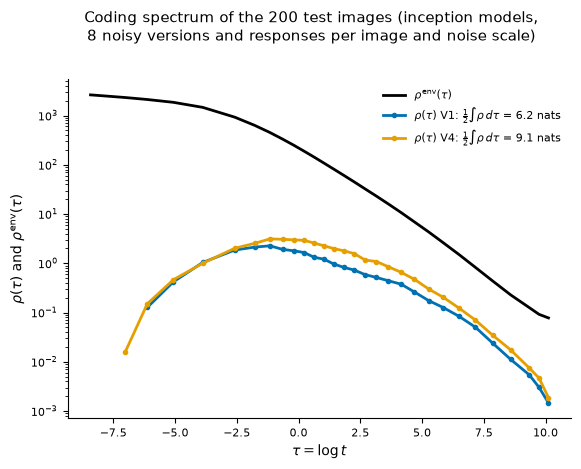

In [6]:
%%time

# 1. the figure, also saved
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
fig, plotted = plot_coding_spectrum(spectra, PARAMS)
fig.savefig(
    figure_dir / "coding_spectrum.png", dpi=PARAMS["file_dpi"], bbox_inches="tight"
)

# 2. for each area: ½ ∫ ρ dτ in nats (and bits), with its standard error
for area, spectrum in spectra.items():
    mean, sem = compute_information(spectrum.env - spectrum.coded, spectrum.log_tau)
    bits = mean / torch.log(torch.tensor(2.0))
    print(f"{area}: ½∫ρ dτ = {mean:.2f} ± {sem:.2f} nats ({bits:.1f} bits)")

## 6. Conclusion

* **The coding spectrum is a bump.** For both areas, $\rho(\tau)$ rises from about zero at the finest levels, peaks at $\log t \approx -1.2$ (2.3 for V1, 3.1 for V4) and falls to about 0.002 at $\log t = 10$, far below the envelope spectrum.
* **V4 leans toward high $\log t$.** The two curves are the same up to $\log t \approx -2.6$; above, V4's is higher, about twice V1's from $\log t \approx 0.6$ to 3.2.
* **The mutual information.** $\tfrac12 \int \rho\, d\tau$ = 6.16 ± 0.18 nats (8.9 bits) for V1 and 9.11 ± 0.23 nats (13.1 bits) for V4: the 50 neurons of V4 carry about 1.5 times more information about the image than the 50 of V1.
* **Caveat: the fine end.** At the finest levels ($\log t \le -6$) the measured $\rho$ is within about 0.15 of zero, and negative at the 2–3 finest levels (not drawn): there, the errors with and without the responses (about 2600) differ by less than the precision of the networks, so the integrals may miss information carried at the finest scales.

**Next steps**: resolve the fine end, for example with a denoiser that is more precise at small noise.